# Splitting the Dinosaur lottery into Gates of Lodore and the Yampa

Gates of Lodore (the Green) and the Yampa share one permit lottery, RIDB 250014. RIDB's reservation files record one launch date per application and per permit, but not which river it is for. `max_float.ingest` splits them in two steps:

1. **Applications**: a two-component Poisson finite mixture model (FMM), fitted by EM, in `dinosaur.mixture`.
2. **Permits**: each permit's trip length, in `dinosaur.river`.

This notebook walks through both with the package's own functions. It reads `data/applications.csv` and `data/applications_cleaned.csv`; build them first with `uv run python -m max_float.ingest.reservations` and `uv run python -m max_float.ingest.clean`.

In [1]:
import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from max_float.ingest import dinosaur, reservations

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"

LODORE, YAMPA, COMBINED, INK, MUTED = (
    "#2a78d6",
    "#eb6834",
    "#a3a29c",
    "#0b0b0b",
    "#52514e",
)
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": MUTED,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "legend.frameon": False,
        "lines.linewidth": 2,
        "figure.dpi": 110,
    }
)

raw = pd.read_csv(DATA / "applications.csv", parse_dates=["date"])
cleaned = pd.read_csv(DATA / "applications_cleaned.csv", parse_dates=["date"])
combined = raw[raw.ridb_id == int(dinosaur.RIDB_ID)].set_index("date")

## 1. The data before the split

The lottery covers each river's high-use season (`dinosaur.season`):

| | First launch | Last launch |
|---|---|---|
| Gates of Lodore | second Monday of May | second Friday of September |
| Yampa | second Monday of May | second Saturday of July |

So applications for launch dates after the Yampa's last launch can only be for Gates of Lodore. Before that, every date's count mixes the two rivers.

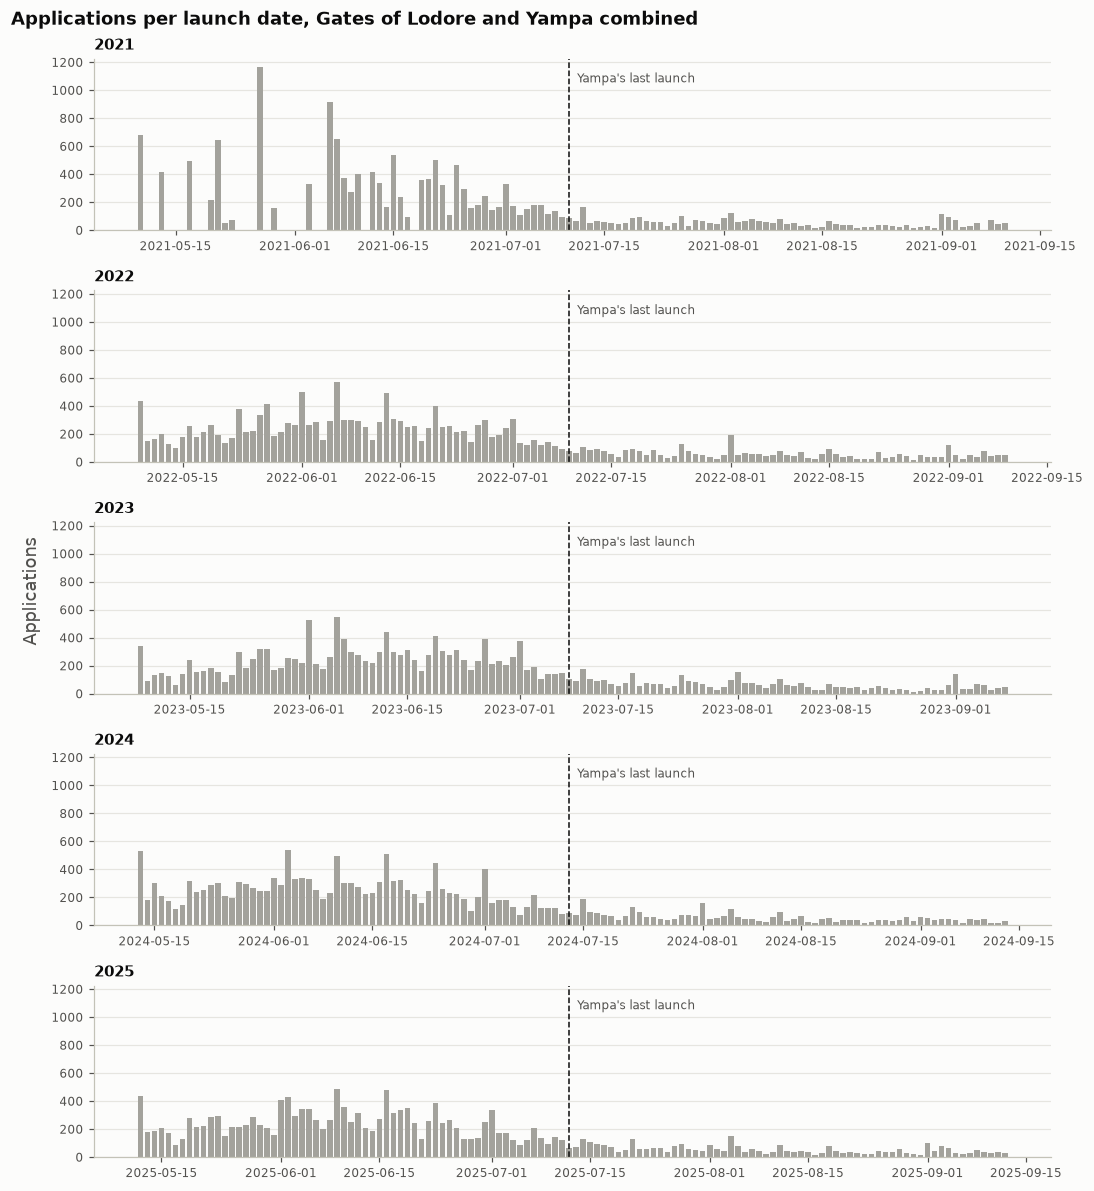

In [2]:
years = range(2021, 2026)
fig, axes = plt.subplots(len(years), 1, figsize=(10, 11), sharey=True)
for ax, year in zip(axes, years):
    start, yampa_end, lodore_end = dinosaur.season(year)
    days = combined.loc[str(start) : str(lodore_end), "applications"]
    ax.bar(days.index, days, width=0.8, color=COMBINED, label="Both rivers, combined")
    ax.axvline(
        yampa_end + datetime.timedelta(hours=12), color=INK, linewidth=1, linestyle="--"
    )
    ax.set_title(str(year), fontsize=10)
    ax.text(
        yampa_end,
        ax.get_ylim()[1] * 0.92,
        "  Yampa's last launch",
        fontsize=8,
        color=MUTED,
        va="top",
    )
    ax.tick_params(labelsize=8)
fig.suptitle(
    "Applications per launch date, Gates of Lodore and Yampa combined",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.supylabel("Applications", color=MUTED)
fig.tight_layout()

Demand peaks in late May and June and falls through the summer. 2021 has gaps: some May and June dates weren't offered that year, so the model leaves out dates with no applications. There is also a strong weekly rhythm, shown next.

## 2. The weekday effect

Monday launches draw far more applications than other days. Dates after the Yampa's last launch are all Gates of Lodore, so they show the weekday pattern without the mixture getting in the way. Each bar compares a weekday's applications with the dates on either side of it (a centered 7-day mean), which removes the seasonal trend. It uses Gates of Lodore-only dates from 2021–2025.

/var/folders/z1/3d1wc39s3lq0z1c9q2hxqrkh0000gn/T/ipykernel_1483/441128763.py:10: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  by_weekday = ratio.groupby(ratio.index.dayofweek).mean()


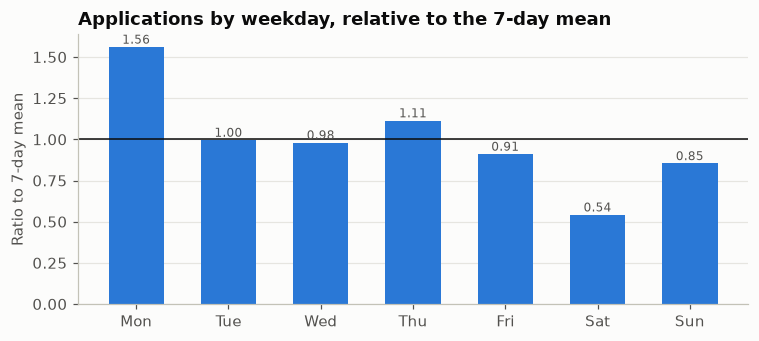

In [3]:
ratios = []
for year in years:
    _, yampa_end, lodore_end = dinosaur.season(year)
    days = combined.loc[
        str(yampa_end + datetime.timedelta(1)) : str(lodore_end), "applications"
    ].astype(float)
    trend = days.rolling(7, center=True).mean()
    ratios.append((days / trend).dropna())
ratio = pd.concat(ratios)
by_weekday = ratio.groupby(ratio.index.dayofweek).mean()
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(names, by_weekday.values, width=0.6, color=LODORE)
ax.axhline(1, color=INK, linewidth=1)
for x, value in enumerate(by_weekday.values):
    ax.text(x, value + 0.02, f"{value:.2f}", ha="center", fontsize=8, color=MUTED)
ax.set_title("Applications by weekday, relative to the 7-day mean")
ax.set_ylabel("Ratio to 7-day mean")
fig.tight_layout()

A model without a weekday term would read Monday spikes as a change in the river mix. So the model shares one weekday effect between both rivers.

## 3. The model

For each season separately, the applications on launch date $d$ are modeled as

$$
n_d \sim \text{Poisson}\big(\lambda_L(d) + \lambda_Y(d)\big),\qquad
\log \lambda_r(d) = a_r + b_r t_d + c_r t_d^2 + w_{\text{weekday}(d)},
$$

where $t_d$ is the fraction of the season elapsed, each river $r$ has its own curve $(a_r, b_r, c_r)$, and the weekday effects $w$ are shared. $\lambda_Y(d) = 0$ after the Yampa's last launch.

This is a finite mixture: each application belongs to one of two rivers, and the river is a hidden label. **EM** (expectation–maximization) fits it by alternating two steps:

- **E-step**: give each date's applications to the rivers in proportion to their current fitted means, a Gates of Lodore share of $\lambda_L(d) / (\lambda_L(d) + \lambda_Y(d))$.
- **M-step**: refit both curves and the weekday effects by Poisson regression on those allocated counts (`dinosaur.poisson_fit`, Newton's method).

It starts with every overlap date split 50/50 and stops when no date's share moves by more than $10^{-9}$. The Lodore-only dates pin down the Gates of Lodore curve and the weekday effects. The Yampa curve absorbs what is left over in the overlap.

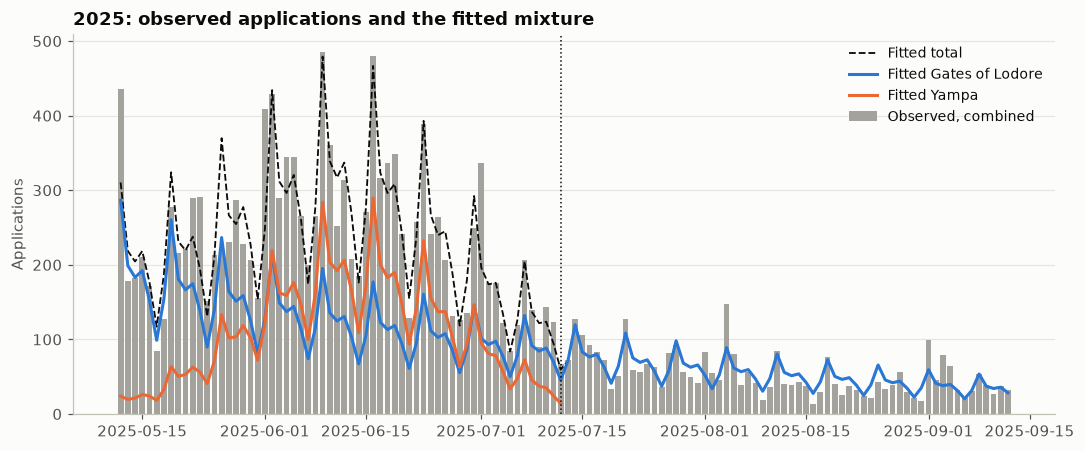

In [4]:
year = 2025
start, yampa_end, lodore_end = dinosaur.season(year)
season_days = combined.loc[str(start) : str(lodore_end), "applications"]
counts = {date.date(): int(n) for date, n in season_days.items() if n > 0}
fit = pd.DataFrame(dinosaur.mixture(counts), index=["lodore", "yampa"]).T
fit.index = pd.to_datetime(fit.index)
fit["observed"] = pd.Series(counts).set_axis(fit.index)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(fit.index, fit.observed, width=0.8, color=COMBINED, label="Observed, combined")
ax.plot(
    fit.index,
    fit.lodore + fit.yampa,
    color=INK,
    linewidth=1.2,
    linestyle="--",
    label="Fitted total",
)
ax.plot(fit.index, fit.lodore, color=LODORE, label="Fitted Gates of Lodore")
overlap = fit.index <= pd.Timestamp(yampa_end)
ax.plot(fit.index[overlap], fit.yampa[overlap], color=YAMPA, label="Fitted Yampa")
ax.axvline(
    yampa_end + datetime.timedelta(hours=12), color=INK, linewidth=1, linestyle=":"
)
ax.set_title(f"{year}: observed applications and the fitted mixture")
ax.set_ylabel("Applications")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

### From fitted lines to a split for each day

The split is done date by date, not with one overall fraction. On each launch date $d$, the Yampa fraction is that day's fitted Yampa mean over the fitted total,

$$
p_Y(d) = \frac{\lambda_Y(d)}{\lambda_L(d) + \lambda_Y(d)},
$$

and the observed applications $n_d$ are split as $n_d\,(1 - p_Y(d))$ to Gates of Lodore and $n_d\,p_Y(d)$ to the Yampa. Because both rivers share the weekday effect, it cancels in $p_Y(d)$. So the fraction is a smooth curve even though the fitted lines above zigzag.

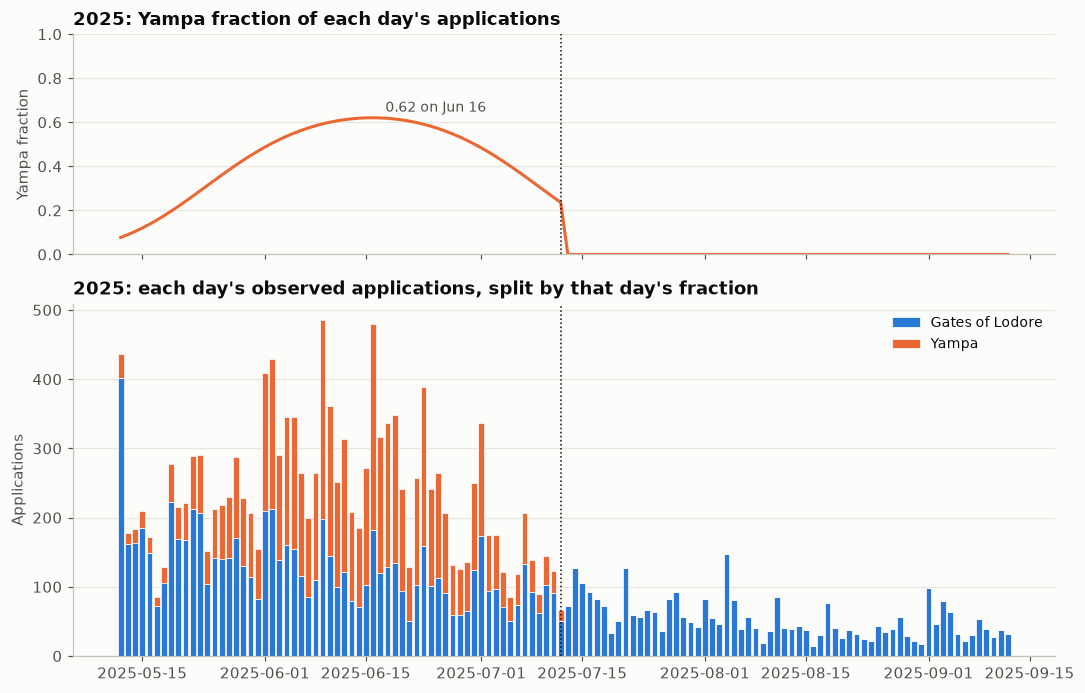

In [5]:
fit["yampa_fraction"] = fit.yampa / (fit.lodore + fit.yampa)
fit["lodore_split"] = fit.observed * (1 - fit.yampa_fraction)
fit["yampa_split"] = fit.observed * fit.yampa_fraction

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(10, 6.4), sharex=True, height_ratios=[1, 1.6]
)
top.plot(fit.index, fit.yampa_fraction, color=YAMPA)
top.set_ylim(0, 1)
top.set_ylabel("Yampa fraction")
top.set_title(f"{year}: Yampa fraction of each day's applications")
peak = fit.yampa_fraction.idxmax()
top.annotate(
    f"{fit.yampa_fraction.max():.2f} on {peak:%b %-d}",
    (peak, fit.yampa_fraction.max()),
    xytext=(8, 4),
    textcoords="offset points",
    fontsize=9,
    color=MUTED,
)

bottom.bar(
    fit.index,
    fit.lodore_split,
    width=0.8,
    color=LODORE,
    edgecolor="#fcfcfb",
    linewidth=0.5,
    label="Gates of Lodore",
)
bottom.bar(
    fit.index,
    fit.yampa_split,
    bottom=fit.lodore_split,
    width=0.8,
    color=YAMPA,
    edgecolor="#fcfcfb",
    linewidth=0.5,
    label="Yampa",
)
bottom.set_ylabel("Applications")
bottom.set_title(
    f"{year}: each day's observed applications, split by that day's fraction"
)
bottom.legend(loc="upper right", fontsize=9)
for ax in (top, bottom):
    ax.axvline(
        yampa_end + datetime.timedelta(hours=12), color=INK, linewidth=1, linestyle=":"
    )
fig.tight_layout()

Below, the overall Yampa share of 2025 applications after each number of EM iterations. The first M-step, fitted to the 50/50 starting split, already moves it to about 0.41. It settles at 0.37 after 100–200 iterations.

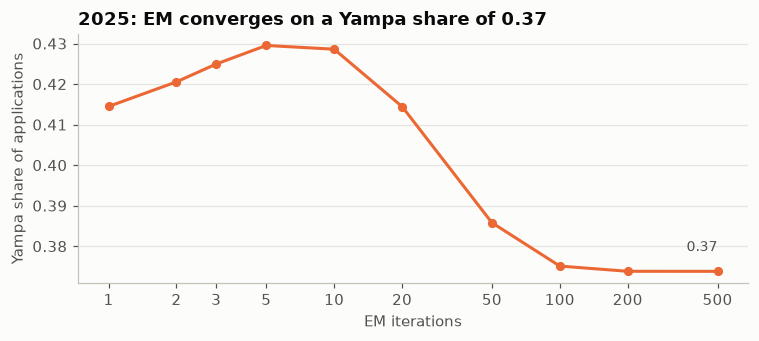

In [6]:
steps = [1, 2, 3, 5, 10, 20, 50, 100, 200, 500]
total = sum(counts.values())
shares = []
for step in steps:
    means = dinosaur.mixture(counts, iterations=step)
    shares.append(sum(counts[d] * y / (l + y) for d, (l, y) in means.items()) / total)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(steps, shares, color=YAMPA, marker="o", markersize=5)
ax.set_xscale("log")
ax.set_xticks(steps, [str(step) for step in steps])
ax.minorticks_off()
ax.set_xlabel("EM iterations")
ax.set_ylabel("Yampa share of applications")
ax.set_title(f"{year}: EM converges on a Yampa share of {shares[-1]:.2f}")
ax.text(
    steps[-1],
    shares[-1] + 0.005,
    f"{shares[-1]:.2f}",
    ha="right",
    fontsize=9,
    color=MUTED,
)
fig.tight_layout()

## 4. The data after the split

`clean.main` applies the fitted shares to every season and writes Gates of Lodore and the Yampa as separate rows in `applications_cleaned.csv`. The histograms below bin each season's launch dates by week and weight them by applications: first the combined data, then the two estimated rivers.

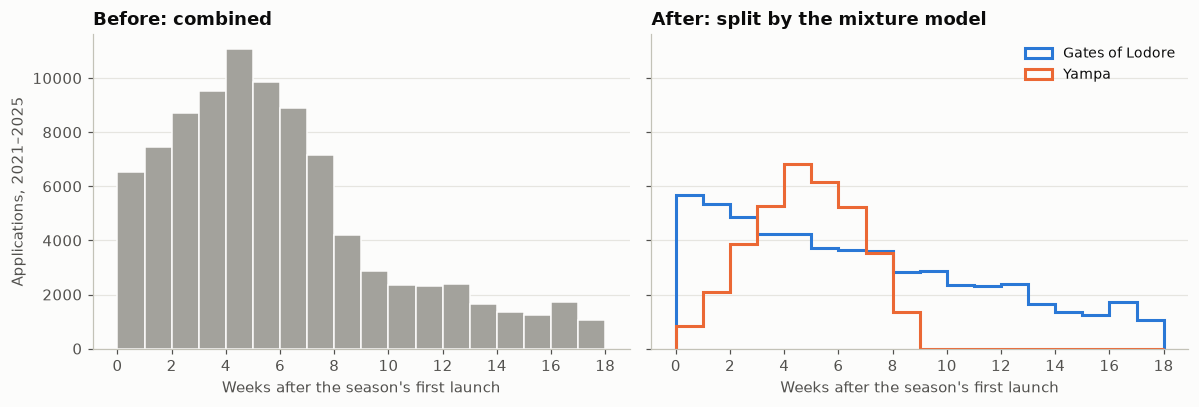

In [7]:
split = cleaned[cleaned.ridb_id == int(dinosaur.RIDB_ID)]
lodore = split[split.river == dinosaur.LODORE].set_index("date").applications
yampa = split[split.river == dinosaur.YAMPA].set_index("date").applications


def weeks_into_season(dates):
    return np.array([(d.date() - dinosaur.season(d.year)[0]).days / 7 for d in dates])


bins = np.arange(0, 19)
fig, (before, after) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
data = combined.loc[combined.applications > 0, "applications"]
before.hist(
    weeks_into_season(data.index),
    bins=bins,
    weights=data,
    color=COMBINED,
    edgecolor="#fcfcfb",
    linewidth=1,
)
before.set_title("Before: combined")
before.set_ylabel("Applications, 2021–2025")
for series, color, label in (
    (lodore, LODORE, "Gates of Lodore"),
    (yampa, YAMPA, "Yampa"),
):
    series = series[series > 0]
    after.hist(
        weeks_into_season(series.index),
        bins=bins,
        weights=series,
        histtype="step",
        color=color,
        linewidth=2,
        label=label,
    )
after.set_title("After: split by the mixture model")
after.legend(fontsize=9)
for ax in (before, after):
    ax.set_xlabel("Weeks after the season's first launch")
    ax.set_xticks(range(0, 19, 2))
fig.tight_layout()

After the split, the Yampa's demand is concentrated in late May and June, around snowmelt, and ends with its season. Gates of Lodore's demand is spread out, declining through the summer. Yearly totals:

In [8]:
totals = (
    split.assign(season=split.date.dt.year)
    .query("season >= 2021")
    .pivot_table(index="season", columns="river", values="applications", aggfunc="sum")[
        [dinosaur.LODORE, dinosaur.YAMPA]
    ]
)
totals["Yampa share"] = totals[dinosaur.YAMPA] / totals.sum(axis=1)
totals.round(2)

river,Green – Gates of Lodore,Yampa,Yampa share
season,,,
2021,9892.5,6924.5,0.41
2022,10493.6,7830.4,0.43
2023,10933.9,7584.1,0.41
2024,12671.8,6174.2,0.33
2025,11242.7,6711.3,0.37


**Caveat.** In the overlap, the split depends on the curve shape. Linear and cubic curves (instead of quadratic) fit the combined counts about as well but move the Yampa share by 0.1–0.3 in either direction. Treat the per-river applications as estimates. One outside figure, such as a season's Yampa total from the Dinosaur River Office, would pin the split down.

## 5. Splitting permits by trip length

Permits record their trip's end date, so they can be split without a model. Trips on the Green from Gates of Lodore are shorter, and Yampa trips run longer. `dinosaur.river` assigns a permit to the Yampa when its trip runs `dinosaur.YAMPA_NIGHTS` (5) nights or more. Trip length here is the end date minus the start date as RIDB records them, so Gates of Lodore's standard 4-day trip shows up as 3 or 4 nights.

This needs each permit's start and end dates, which only RIDB's raw file has. The next cell downloads the FY2025 file once (about 500 MB, a minute or two) through `reservations.lines` and keeps just the three date columns.

In [9]:
cache = DATA / "dinosaur_permits_2025.csv"
if not cache.exists():
    with reservations.lines(2025) as lines:
        records = [
            {key: record[key] for key in ("startdate", "enddate", "orderdate")}
            for record in reservations.records(lines, {dinosaur.RIDB_ID})
            if record["inventorytype"] == "PERMIT"
        ]
    pd.DataFrame(records).to_csv(cache, index=False)

permits = pd.read_csv(cache, dtype=str).fillna("")
permits["river"] = [dinosaur.river(record) for record in permits.to_dict("records")]
permits["launch"] = pd.to_datetime(permits.startdate.str[:10])
permits["nights"] = (pd.to_datetime(permits.enddate.str[:10]) - permits.launch).dt.days
start, yampa_end, lodore_end = dinosaur.season(2025)
permits["period"] = np.select(
    [
        permits.launch.dt.date.between(start, yampa_end),
        permits.launch.dt.date.between(yampa_end + datetime.timedelta(1), lodore_end),
    ],
    ["Both high-use seasons", "Gates of Lodore high-use only"],
    "Outside the lottery season",
)
permits.groupby(["period", "river"]).size().unstack(fill_value=0)

river,Green – Gates of Lodore,Yampa
period,,
Both high-use seasons,319,75
Gates of Lodore high-use only,313,91
Outside the lottery season,145,80


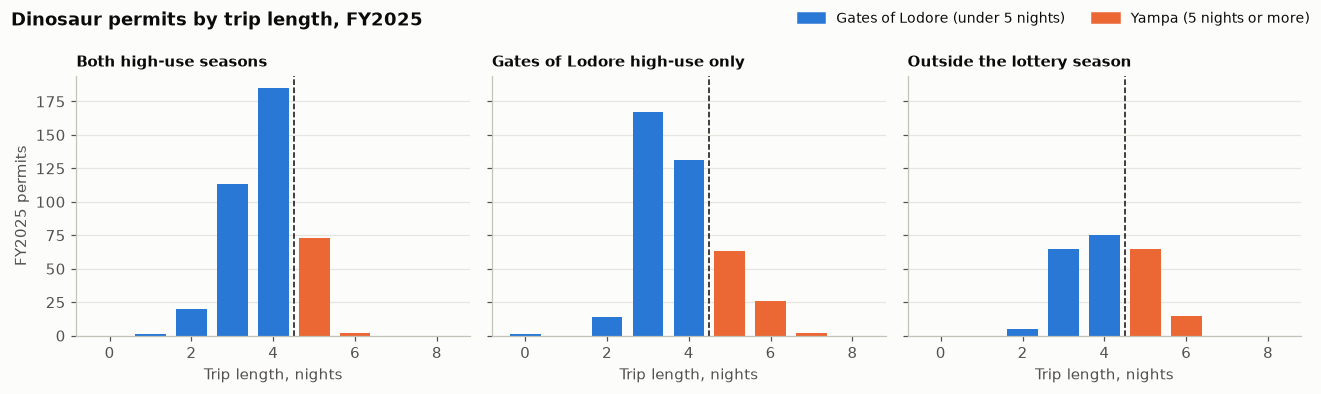

In [10]:
periods = [
    "Both high-use seasons",
    "Gates of Lodore high-use only",
    "Outside the lottery season",
]
nights = np.arange(0, 9)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, period in zip(axes, periods):
    trips = (
        permits[permits.period == period]
        .nights.value_counts()
        .reindex(nights, fill_value=0)
    )
    colors = [YAMPA if n >= dinosaur.YAMPA_NIGHTS else LODORE for n in nights]
    ax.bar(nights, trips.values, width=0.75, color=colors)
    ax.axvline(dinosaur.YAMPA_NIGHTS - 0.5, color=INK, linewidth=1, linestyle="--")
    ax.set_title(period, fontsize=10)
    ax.set_xlabel("Trip length, nights")
axes[0].set_ylabel("FY2025 permits")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (LODORE, YAMPA)]
fig.legend(
    handles,
    ["Gates of Lodore (under 5 nights)", "Yampa (5 nights or more)"],
    loc="upper right",
    fontsize=9,
    ncol=2,
)
fig.suptitle(
    "Dinosaur permits by trip length, FY2025", x=0.01, ha="left", fontweight="bold"
)
fig.tight_layout()

Trips of 5 nights or more appear almost only while the Yampa's high-use season runs. After it ends, the longer trips that remain are low-use Yampa permits, which the same rule catches.

The lottery winners' own permits, those ordered before unclaimed trips opened on March 6, check the rule against the daily quotas. Stacked by river per launch date, they should come to about 2 Gates of Lodore launches plus 1 Yampa launch while both seasons run, and 2 Gates of Lodore launches after.

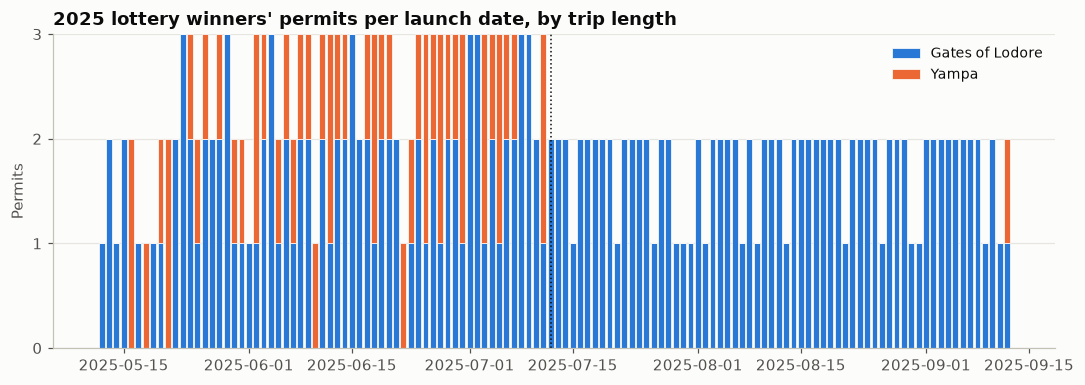

In [11]:
winners = permits[
    (permits.orderdate.str[:10] < "2025-03-06")
    & permits.launch.dt.date.between(start, lodore_end)
]
daily = (
    winners.groupby(["launch", "river"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[dinosaur.LODORE, dinosaur.YAMPA], fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(
    daily.index,
    daily[dinosaur.LODORE],
    width=0.8,
    color=LODORE,
    edgecolor="#fcfcfb",
    linewidth=0.5,
    label="Gates of Lodore",
)
ax.bar(
    daily.index,
    daily[dinosaur.YAMPA],
    bottom=daily[dinosaur.LODORE],
    width=0.8,
    color=YAMPA,
    edgecolor="#fcfcfb",
    linewidth=0.5,
    label="Yampa",
)
ax.axvline(
    yampa_end + datetime.timedelta(hours=12), color=INK, linewidth=1, linestyle=":"
)
ax.set_yticks([0, 1, 2, 3])
ax.set_ylabel("Permits")
ax.set_title("2025 lottery winners' permits per launch date, by trip length")
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()

## 6. Permits recorded twice

In FY2021 RIDB recorded every Dinosaur permit twice. `clean.doubled` flags a permit's fiscal year when every launch date with permits has an even count; in a normal year about half are odd. Flagged years have their permits halved in `applications_cleaned.csv`.

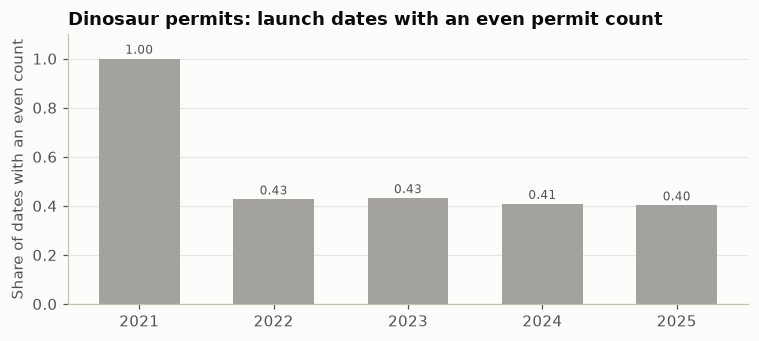

In [12]:
raw_permits = combined[combined.permits > 0].copy()
raw_permits["fiscal_year"] = [
    int(url.split("reservations")[1][:4]) for url in raw_permits.source_url
]
even = raw_permits.groupby("fiscal_year").permits.apply(lambda p: (p % 2 == 0).mean())

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(even.index.astype(str), even.values, width=0.6, color=COMBINED)
for x, value in enumerate(even.values):
    ax.text(x, value + 0.02, f"{value:.2f}", ha="center", fontsize=8, color=MUTED)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Share of dates with an even count")
ax.set_title("Dinosaur permits: launch dates with an even permit count")
fig.tight_layout()